# Flight Tracker Exploration Notebook

Welcome to the interactive environment! Here you can set regions, time periods, simulate historical data scraping, and plot the prices to visualize our moving average analytics.

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Ensure the src/ modules can be imported
project_root = str(Path(os.getcwd()).parent.parent)
if project_root not in sys.path:
    sys.path.append(project_root)

from src.database.db_manager import (
    get_historical_prices,
    setup_database,
)
from src.services.analytics import calculate_moving_average
from src.services.flight_api import fetch_flights
from src.services.routing import generate_routes

setup_database()
print("Environment setup complete!")

Environment setup complete!


## 1. Set Your Search Parameters
Define the region you want to start from, where you want to go, and the travel date. You can also define constraints like the maximum number of stops and maximum travel time in minutes.

In [ ]:
ORIGIN_REGION = "Switzerland"
DEST_REGION = "Norway"
DEPARTURE_DATE = "2026-12-15"
MAX_STOPS = 1
MAX_TRAVEL_TIME_MINS = 300

## 2. Simulate Historical Scraping
Because we need history to calculate moving averages, let's simulate the scraper running every day for the past 14 days. It will automatically filter out flights that exceed your constraints.

In [ ]:
routes = generate_routes(ORIGIN_REGION, DEST_REGION)
print(f"Expanded into {len(routes)} airport-to-airport routes.")

for days_ago in reversed(range(14)):
    simulated_date = (datetime.now() - timedelta(days=days_ago)).isoformat()

    for route_origin, route_dest in routes:
        # Fetch mock prices
        flights = fetch_flights(route_origin, route_dest, DEPARTURE_DATE)

        import sqlite3

        from src.database.db_manager import DB_PATH

        conn = sqlite3.connect(DB_PATH)
        cursor = conn.cursor()
        for f in flights:
            if (
                f.get("stops", 0) > MAX_STOPS
                or f.get("travel_time_minutes", 0) > MAX_TRAVEL_TIME_MINS
            ):
                continue
            cursor.execute(
                """
                INSERT INTO flight_prices 
                (origin, destination, departure_date, return_date, price, currency, stops, travel_time_minutes, scraped_at)
                VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
            """,
                (
                    f["origin"],
                    f["destination"],
                    f["departure_date"],
                    f.get("return_date"),
                    f["price"],
                    f.get("currency", "USD"),
                    f.get("stops", 0),
                    f.get("travel_time_minutes", 0),
                    simulated_date,
                ),
            )
        conn.commit()
        conn.close()
print("Simulated 14 days of historical data gathering!")

Expanded into 16 airport-to-airport routes.
Simulated 14 days of historical data gathering!


## 3. Find the Best Combinations Today
Now let's find the absolute cheapest routes available right now for your selected date that met your constraints.

In [ ]:
import sqlite3

from src.database.db_manager import DB_PATH

conn = sqlite3.connect(DB_PATH)

query = """
SELECT origin, destination, price, currency, stops, travel_time_minutes, scraped_at 
FROM flight_prices 
WHERE departure_date = ?
ORDER BY scraped_at DESC
LIMIT ?
"""
recent_df = pd.read_sql_query(query, conn, params=[DEPARTURE_DATE, len(routes) * 2])
conn.close()

best_combinations = recent_df.sort_values(by="price").head(40)
print("Top 5 Cheapest Combinations Found Today (Matching Constraints):")
display(best_combinations)

Top 5 Cheapest Combinations Found Today (Matching Constraints):


,origin,destination,price,currency,stops,travel_time_minutes,scraped_at
0,ZRH,OSL,122.0,USD,1,255,2026-06-29T21:22:54.804315
3,ZRH,OSL,122.0,USD,1,295,2026-06-29T21:22:54.804315
1,ZRH,OSL,125.0,USD,0,150,2026-06-29T21:22:54.804315
14,ZRH,SVG,129.0,USD,1,295,2026-06-29T21:22:54.804315
15,ZRH,SVG,129.0,USD,1,280,2026-06-29T21:22:54.804315
27,GVA,OSL,133.0,USD,1,260,2026-06-29T21:22:54.804315
31,GVA,OSL,140.0,USD,1,275,2026-06-29T21:22:54.804315
28,GVA,OSL,140.0,USD,1,260,2026-06-29T21:22:54.804315
29,GVA,OSL,141.0,USD,1,270,2026-06-29T21:22:54.804315
21,BSL,OSL,153.0,USD,1,250,2026-06-29T21:22:54.804315


## 4. Plot Historical Prices & Moving Average
Let's pick the cheapest route from above and visualize its price history over the last 14 days, plotting the actual price against the 3-day moving average.

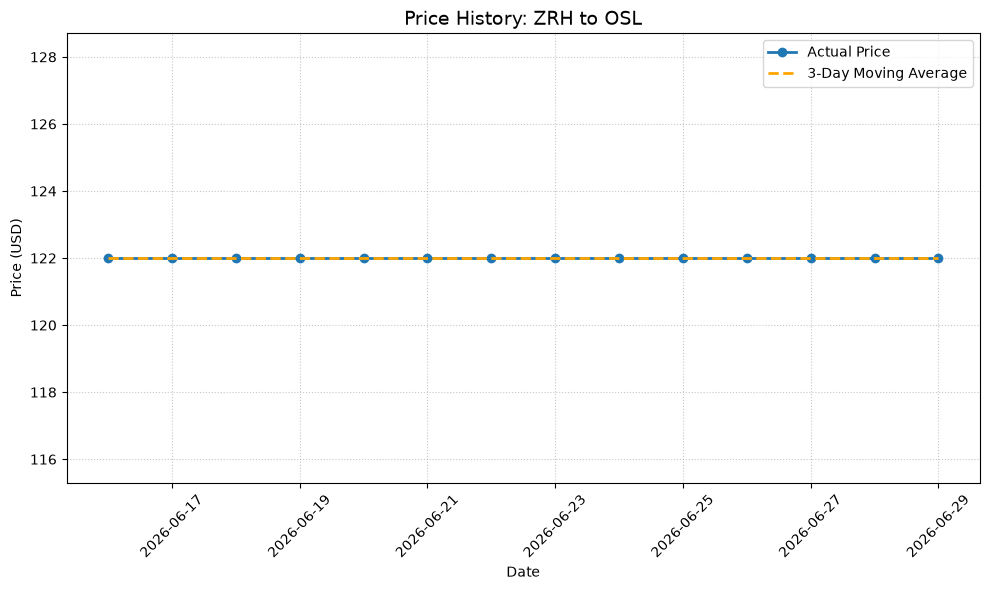

In [ ]:
if best_combinations.empty:
    print(
        "No flights matched your constraints over the last day! Try relaxing stops/time."
    )
else:
    best_origin = best_combinations.iloc[0]["origin"]
    best_dest = best_combinations.iloc[0]["destination"]

    hist_df = get_historical_prices(best_origin, best_dest, DEPARTURE_DATE)

    hist_df["date"] = hist_df["scraped_at"].dt.date
    daily_df = hist_df.groupby("date")["price"].min().reset_index()
    daily_df["scraped_at"] = pd.to_datetime(daily_df["date"])
    daily_df = calculate_moving_average(daily_df, window_size=3)

    plt.figure(figsize=(10, 6))
    plt.plot(
        daily_df["date"],
        daily_df["price"],
        marker="o",
        label="Actual Price",
        linewidth=2,
    )
    plt.plot(
        daily_df["date"],
        daily_df["ma_3"],
        linestyle="--",
        color="orange",
        label="3-Day Moving Average",
        linewidth=2,
    )

    plt.title(f"Price History: {best_origin} to {best_dest}", fontsize=14)
    plt.xlabel("Date")
    plt.ylabel("Price (USD)")
    plt.grid(True, linestyle=":", alpha=0.7)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()